# A One-Week Mini-Project in Bioinformatics

**Project title:** Analysis of the Human TP53 DNA Sequence and Breast Cancer Gene-Expression Data

**Data sources:** NCBI Gene and NCBI Gene Expression Omnibus (GEO)

**Tools used:** Google Colab, Python, pandas and Matplotlib

**Objective:** To analyse basic properties of the human TP53 DNA sequence and explore gene-expression measurements from a breast cancer study using computational methods.

In [ ]:

from google.colab import files

uploaded = files.upload()


Saving TP53.FASTA.txt to TP53.FASTA.txt


In [ ]:

import pandas as pd

fasta_path = "TP53.FASTA.txt"

header = ""
sequence = ""

with open(fasta_path, "r") as file:
    for line in file:
        line = line.strip()
        if line.startswith(">"):
            header = line
        else:
            sequence += line.upper()

# Count the nucleotides
A_count = sequence.count("A")
T_count = sequence.count("T")
G_count = sequence.count("G")
C_count = sequence.count("C")

sequence_length = len(sequence)

# Validate the sequence
valid_bases = set("ATGC")
invalid_characters = sorted(set(sequence) - valid_bases)
is_valid = sequence_length > 0 and len(invalid_characters) == 0

# Calculate GC percentage
gc_percentage = (
    ((G_count + C_count) / sequence_length) * 100)
# Calculate AT percentage
at_percentage= (
  ((A_count + T_count) / sequence_length) * 100)

# Display results
print("TP53 DNA SEQUENCE ANALYSIS")
print("-" * 35)
print("FASTA header:", header)
print("Sequence length:", sequence_length)
print("A count:", A_count)
print("T count:", T_count)
print("G count:", G_count)
print("C count:", C_count)

print("GC percentage:", gc_percentage)
print("AT percentage:", at_percentage)

# Save results in a CSV file
summary = pd.DataFrame([{
    "FASTA_header": header,
    "Sequence_length": sequence_length,
    "A_count": A_count,
    "T_count": T_count,
    "G_count": G_count,
    "C_count": C_count,
    "Valid_DNA": is_valid,
    "Invalid_characters": ",".join(invalid_characters),
    "GC_percentage": gc_percent
}])

summary.to_csv("TP53_sequence_summary.csv", index=False)

print("\nSummary saved as TP53_sequence_summary.csv")


TP53 DNA SEQUENCE ANALYSIS
-----------------------------------
FASTA header: >NC_060941.1:c7591594-7572544 TP53 [organism=Homo sapiens] [GeneID=7157] [chromosome=17]
Sequence length: 38121
A count: 9925
T count: 9374
G count: 9550
C count: 9272
GC percentage: 49.374360588651925
AT percentage: 50.625639411348075

Summary saved as TP53_sequence_summary.csv


In [ ]:

from google.colab import files
files.download("TP53_sequence_summary.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

!wget https://ftp.ncbi.nlm.nih.gov/geo/series/GSE42nnn/GSE42568/matrix/GSE42568_series_matrix.txt.gz
!gunzip GSE42568_series_matrix.txt.gz

--2026-10-20 05:20:59--  https://ftp.ncbi.nlm.nih.gov/geo/series/GSE42nnn/GSE42568/matrix/GSE42568_series_matrix.txt.gz
Resolving ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)... 130.14.250.7, 130.14.250.10, 2607:f220:41e:250::12, ...
Connecting to ftp.ncbi.nlm.nih.gov (ftp.ncbi.nlm.nih.gov)|130.14.250.7|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 22565943 (22M) [application/x-gzip]
Saving to: ‘GSE42568_series_matrix.txt.gz’

GSE42568_series_mat 100%[===================>]  21.52M  20.1MB/s    in 1.1s    

2026-10-20 05:21:01 (20.1 MB/s) - ‘GSE42568_series_matrix.txt.gz’ saved [22565943/22565943]

gzip: GSE42568_series_matrix.txt already exists; do you wish to overwrite (y or n)? ^C


In [ ]:
!head -n 15 GSE42568_series_matrix.txt


!Series_title	"Breast Cancer Gene Expression Analysis"
!Series_geo_accession	"GSE42568"
!Series_status	"Public on May 26 2013"
!Series_submission_date	"Nov 27 2012"
!Series_last_update_date	"Mar 25 2019"
!Series_pubmed_id	"23740839"
!Series_summary	"Analysis of 104 breast cancer biopsies (removed prior to any treatment with tamoxifen or chemotherapeutic agents) from patients aged between 31 years and 89 years at the time of diagnosis (mean age = 58 years). Twenty were less than 50 years and seventy-seven women were 50 years, or older, at diagnosis. The size of the tumours ranged between 0.6 cm and 8.0 cm (mean = 2.79 cm). Eighteen tumours were T1 (<2 cm) in maximal dimension; 83 were T2 (2–5 cm) and 3 tumours were T3 (>5 cm). Eighty-two were invasive ductal carcinoma, 17 were invasive lobular and five were tumours of special type (two tubular and three mucinous). Eleven tumours were grade 1; 40 were grade 2; and 53 were grade 3. Sixty-seven tumours were oestrogen receptor (ER) positive

In [ ]:
import pandas as pd


df = pd.read_csv("GSE42568_series_matrix.txt", sep="\t", comment="!", low_memory=False)


df.rename(columns={df.columns[0]: "ID_REF"}, inplace=True)


print("Dataset Shape (Rows, Columns):", df.shape)
print("\nMissing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())


df.head()

Dataset Shape (Rows, Columns): (54675, 122)

Missing values: 0
Duplicate rows: 0


,ID_REF,GSM1045191,GSM1045192,GSM1045193,GSM1045194,GSM1045195,GSM1045196,GSM1045197,GSM1045198,GSM1045199,...,GSM1045302,GSM1045303,GSM1045304,GSM1045305,GSM1045306,GSM1045307,GSM1045308,GSM1045309,GSM1045310,GSM1045311
0,1007_s_at,5.640239,3.557696,3.132007,6.865108,4.955184,5.573674,4.714100,5.234298,5.050853,...,6.953623,7.007825,7.867141,8.436528,6.020774,7.168925,7.935322,6.937005,8.822155,7.834706
1,1053_at,5.074866,4.984593,5.109481,5.473609,5.348400,5.572707,5.675239,5.792026,6.185706,...,5.453186,5.572707,5.471505,6.830667,6.855478,5.358832,4.804079,5.488895,5.575357,5.687899
2,117_at,4.191770,4.269061,4.131843,3.616546,4.296657,4.184048,4.000772,4.984939,4.958126,...,4.209247,3.946714,5.186979,3.888039,4.131843,4.131843,3.967933,4.392234,4.269244,4.264560
3,121_at,3.574706,4.065623,3.574706,3.574706,3.799293,3.803312,3.643243,4.053245,3.574706,...,3.574706,3.574706,3.574706,3.574706,3.574706,3.502410,3.574706,3.579242,3.574706,3.574706
4,1255_g_at,2.312812,2.409371,2.312812,2.312812,2.349630,2.312812,2.312812,2.312812,2.312812,...,2.312812,2.312812,2.312812,2.312812,2.312812,2.312812,2.312812,2.312812,2.312812,2.312812


In [ ]:
normal_samples = []
tumor_samples = []

with open("GSE42568_series_matrix.txt") as f:
    for line in f:
        if line.startswith("!Sample_source_name_ch1"):
            labels = line.strip().split("\t")[1:]
        if line.startswith("!Sample_geo_accession"):
            ids = line.strip().split("\t")[1:]

for i in range(len(ids)):
    sample_id = ids[i].replace('"', '')
    label = labels[i].lower()
    if "normal" in label:
        normal_samples.append(sample_id)
    else:
        tumor_samples.append(sample_id)

print("Normal:", len(normal_samples))
print("Tumor:", len(tumor_samples))

df["Normal_Mean"] = df[normal_samples].mean(axis=1)
df["Tumor_Mean"] = df[tumor_samples].mean(axis=1)
df["Mean_Difference"] = df["Tumor_Mean"] - df["Normal_Mean"]

top_probes = df.sort_values(by="Mean_Difference", ascending=False).head(5)
print(top_probes[["ID_REF", "Normal_Mean", "Tumor_Mean", "Mean_Difference"]])

df[["ID_REF", "Normal_Mean", "Tumor_Mean", "Mean_Difference"]].head(100).to_csv("expression_summary.csv", index=False)

Normal: 17
Tumor: 104
            ID_REF  Normal_Mean  Tumor_Mean  Mean_Difference
11098    201650_at     6.287653   11.739673         5.452020
54294     37892_at     3.601280    8.978260         5.376979
41419    232165_at     3.840829    9.124154         5.283325
11287  201839_s_at     6.767673   11.924118         5.156445
41418  232164_s_at     4.175217    9.211906         5.036688


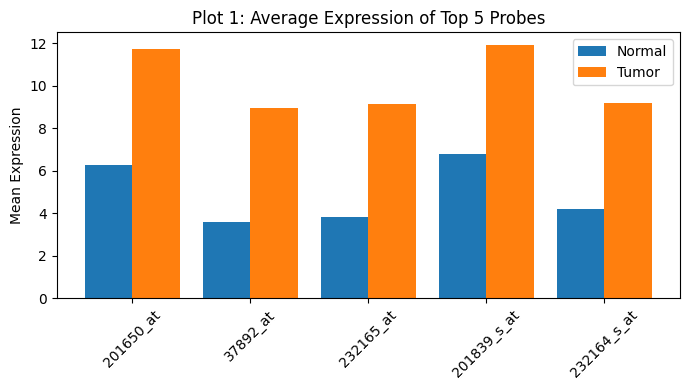

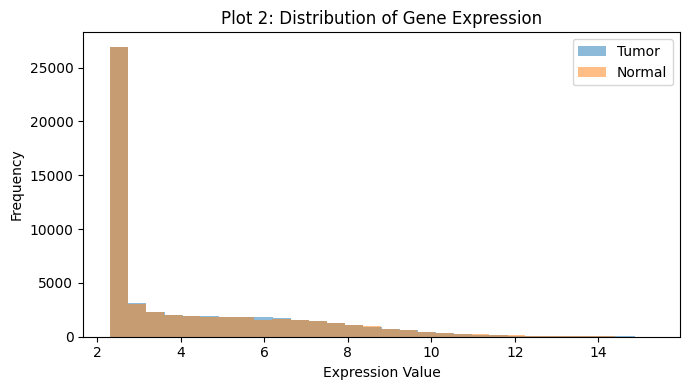

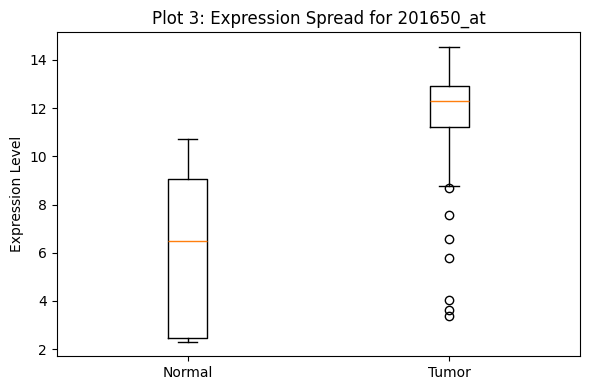

In [ ]:
import matplotlib.pyplot as plt

top5 = df.sort_values(by="Mean_Difference", ascending=False).head(5)

x = list(range(len(top5)))

plt.figure(figsize=(7, 4))
plt.bar([i - 0.2 for i in x], top5["Normal_Mean"], width=0.4, label="Normal")
plt.bar([i + 0.2 for i in x], top5["Tumor_Mean"], width=0.4, label="Tumor")
plt.xticks(x, top5["ID_REF"], rotation=45)
plt.ylabel("Mean Expression")
plt.title("Plot 1: Average Expression of Top 5 Probes")
plt.legend()
plt.tight_layout()
plt.savefig("plot1_bar.png")
plt.show()

plt.figure(figsize=(7, 4))
plt.hist(df[tumor_samples[0]].dropna(), bins=30, alpha=0.5, label="Tumor")
plt.hist(df[normal_samples[0]].dropna(), bins=30, alpha=0.5, label="Normal")
plt.xlabel("Expression Value")
plt.ylabel("Frequency")
plt.title("Plot 2: Distribution of Gene Expression")
plt.legend()
plt.tight_layout()
plt.savefig("plot2_histogram.png")
plt.show()

top_gene = top5.iloc[0]["ID_REF"]
normal_data = df.loc[df["ID_REF"] == top_gene, normal_samples].values.flatten()
tumor_data = df.loc[df["ID_REF"] == top_gene, tumor_samples].values.flatten()

plt.figure(figsize=(6, 4))
plt.boxplot([normal_data, tumor_data], tick_labels=["Normal", "Tumor"])
plt.ylabel("Expression Level")
plt.title("Plot 3: Expression Spread for " + str(top_gene))
plt.tight_layout()
plt.savefig("plot3_boxplot.png")
plt.show()